# MoveWell: planning a Singapore moving company from HDB data
**OPIM348 Supply Chain Analytics · term project · SMU**

**The question.** A new moving company has to buy fixed assets (trucks, crews) before it knows how much work it will win. How many household moves will Singapore have over the next five years (2027–2031)? How big should the fleet be? And does the investment survive the risks: a weak launch, recessions, rule changes?

**What this notebook contains (everything in one file):** the data (embedded, with code to re-download it from the official source), every model, every test, the results, and explanations.

| § | Section | Methods |
|---|---|---|
| 1 | Data | official sources, embedded snapshot, optional live re-download and verification |
| 2 | Estimated moves 2007–2026 | turning housing records into household moves |
| 3 | Why moves happen | MOP wave; resale chances by flat age, two eras (36 years) |
| 4 | Demand model | structural cohort model × seasonality × AR(1) market mood |
| 5 | **Forecast testing** | monthly hold-out, rolling-origin 1–5 year backtest, prediction-interval coverage |
| 6 | Town clusters and depots | k-means (k-means++, silhouette), weighted k-means |
| 7 | Global and policy indicators | recession and rule-change effects (regression with lag), robustness |
| 8 | Five-year forecast | Monte Carlo, 2,000 futures |
| 9 | Fleet decision | newsvendor, four fleet strategies, NPV / chance of loss / CVaR / IRR, tornado, stress tests, seed robustness |
| 10 | Summary and app consistency check | key results; the interactive app reproduces these numbers |

**How to reproduce.** Run all cells from the top (*Run All*); it takes about a minute. It needs only `numpy`, `pandas` and `matplotlib` (`requests` for the optional re-download). Every random draw is seeded, so a re-run gives identical numbers. Data is a snapshot pulled from data.gov.sg on 27 Oct 2026, embedded in §1; set `USE_LIVE_DATA = True` to rebuild it from the official files instead.

**Companion app.** `app/MoveWell_HDB_Moving_Demand.html` presents the same models interactively (map, sliders, live re-simulation). §10 checks that the app and this notebook agree.

In [1]:
import json, math, gzip, base64, io, sys, time, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

C1, C2, C3, C4, C5, GREY = '#1F9A76', '#D9604C', '#3577C2', '#B9860C', '#9256C2', '#9C9385'   # the app's palette
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 11, 'axes.titleweight': 'bold'})
pd.options.display.float_format = '{:,.3f}'.format
sgd = lambda v: f'−S${-v:,.0f}' if v < 0 else f'S${v:,.0f}'      # money format
print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}')

Python 3.13.16 | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2


## 1. Data
All data is free and official. We aggregate the raw files to what the models need (monthly counts, yearly completions, quarterly sales).

| Dataset | Source (data.gov.sg id) | Used for |
|---|---|---|
| HDB resale transactions, 1990–2026 (≈988,000 sales) | HDB · `d_ebc5ab87086db484f88045b47411ebc5`, `d_43f493c6c50d54243cc1eab0df142d6a`, `d_2d5ff9ea31397b66239f245f57751537`, `d_ea9ed51da2787afaf8e51f827c304208`, `d_8b84c4ee58e3cfc0ece0d773c8ca6abc` | resale moves, resale chances by flat age |
| HDB Property Information (blocks, units, year completed) | `d_17f5382f26140b1fdae0ba2ef6239d2f` | BTO move-ins, MOP pipeline |
| Renting out of flats (by town, monthly, 2021+) | `d_c9f57187485a850908655db0e8cfe651` | rental moves |
| Renting out of flat approvals (national, quarterly, 2007–2021) | `d_dad4567fc02596774010f765567780e3` | rental moves before 2021 |
| URA private residential transactions (quarterly) | `d_7c69c943d5f0d89d6a9a773d2b51f337` | condo and landed moves |
| Census 2020 households by planning area and dwelling type | `d_388f9c61f437a588b47b008a012d13fa` | splitting private moves across regions |
| Real GDP growth (SingStat) | `d_1f924c084e848ba3a27068d801c43f43` | recession years |
| Dated rule changes 1989–2026 | LKY School case study *Public Housing in Singapore*; MND/HDB/URA announcements (listed in §7) | policy effects |
| MOP validation | OrangeTee, *HDB Market Outlook 2026* | checking our MOP counts |

**Aggregations.** `resale` = transactions per town per month from Jan 2017; `resaleOld` = national transactions per month 1990–2016; `cohorts` = national resales by lease-start year × sale year; `flatTypes` = resales per town by flat type since 2017; `rental` = approvals per town per month from Jan 2021; `rentalOldQ` = national approvals per quarter 2007–2021; `blocks` = residential units per town per completion year; `compNat` = flats completed per year nationally; `privateQ(Old)` = URA resales and completed new sales per quarter; `census` = HDB, condo and landed households per planning area; `gdp` = real GDP growth per year.

**Cut-off.** Data runs to September 2026. October 2026 was incomplete on the pull date and is dropped from modelling.

In [2]:
USE_LIVE_DATA = False   # False: use the embedded snapshot (exact reproduction). True: re-download from data.gov.sg (needs internet + requests).

### 1a. Re-downloading from the official source (optional)
This is the code that built the snapshot. With `USE_LIVE_DATA = True` it downloads the raw files (about 100 MB; data.gov.sg rate-limits, so it waits and retries), aggregates them to the same cut-off, and compares the result with the embedded snapshot.

In [3]:
API = 'https://api-open.data.gov.sg/v1/public/api/datasets/{}/{}'
SOURCES = {'resale_1990_1999': 'd_ebc5ab87086db484f88045b47411ebc5', 'resale_2000_2012': 'd_43f493c6c50d54243cc1eab0df142d6a',
           'resale_2012_2014': 'd_2d5ff9ea31397b66239f245f57751537', 'resale_2015_2016': 'd_ea9ed51da2787afaf8e51f827c304208',
           'resale_2017_on': 'd_8b84c4ee58e3cfc0ece0d773c8ca6abc', 'rental_2021_on': 'd_c9f57187485a850908655db0e8cfe651',
           'rental_q_2007_2021': 'd_dad4567fc02596774010f765567780e3', 'hdb_blocks': 'd_17f5382f26140b1fdae0ba2ef6239d2f',
           'ura_private_q': 'd_7c69c943d5f0d89d6a9a773d2b51f337', 'census2020_hh': 'd_388f9c61f437a588b47b008a012d13fa',
           'gdp_growth': 'd_1f924c084e848ba3a27068d801c43f43'}

def download_csv(name):
    import requests
    ds = SOURCES[name]
    for _ in range(15):
        r = requests.get(API.format(ds, 'poll-download'), timeout=60)
        if r.status_code == 429: time.sleep(10); continue
        url = (r.json().get('data') or {}).get('url')
        if url: return pd.read_csv(io.BytesIO(requests.get(url, timeout=600).content), low_memory=False)
        requests.get(API.format(ds, 'initiate-download'), timeout=60); time.sleep(5)
    raise RuntimeError(f'could not download {name}')

def build_from_source(last_month='2026-10', last_q='2026-Q3', last_year=2026):
    """Download every raw file and aggregate it exactly as the snapshot was built."""
    cols = ['month', 'town', 'flat_type', 'lease_commence_date']
    old = pd.concat([download_csv(n)[cols] for n in ['resale_1990_1999', 'resale_2000_2012', 'resale_2012_2014', 'resale_2015_2016']])
    new = download_csv('resale_2017_on')[cols]; new = new[new.month <= last_month]
    m17 = pd.period_range('2017-01', last_month, freq='M').astype(str)
    d = {'resale': {t: g.month.value_counts().reindex(m17, fill_value=0).astype(int).tolist() for t, g in new.groupby('town')},
         'resaleOld': old.month.value_counts().reindex(pd.period_range('1990-01', '2016-12', freq='M').astype(str), fill_value=0).astype(int).tolist(),
         'flatTypes': {t: g.flat_type.value_counts().astype(int).to_dict() for t, g in new.groupby('town')}}
    allr = pd.concat([old, new]).assign(sy=lambda x: x.month.str[:4].astype(int))
    coh = allr.groupby(['lease_commence_date', 'sy']).size()
    d['cohorts'] = {str(L): {str(y): int(n) for y, n in g.droplevel(0).items()} for L, g in coh.groupby(level=0)}
    rt = download_csv('rental_2021_on'); rt['m'] = rt.rent_approval_date.astype(str).str[:7]; rt = rt[rt.m <= '2026-09']
    mR = pd.period_range('2021-01', '2026-09', freq='M').astype(str)
    d['rental'] = {t: g.m.value_counts().reindex(mR, fill_value=0).astype(int).tolist() for t, g in rt.groupby('town')}
    rq = download_csv('rental_q_2007_2021')
    d['rentalOldQ'] = rq.assign(n=pd.to_numeric(rq.no_of_approvals, errors='coerce').fillna(0)).groupby('quarter').n.sum().astype(int).to_dict()
    bl = download_csv('hdb_blocks'); bl = bl[bl.residential.eq('Y')].assign(u=lambda x: pd.to_numeric(x.total_dwelling_units, errors='coerce').fillna(0))
    bl = bl[bl.year_completed <= last_year]
    d['blocks'] = {}
    for code, g in bl.groupby('bldg_contract_town'):
        by = g.groupby('year_completed').u.sum()
        d['blocks'][code] = {**{str(int(y)): int(u) for y, u in by.items() if y >= 1985 and u > 0}, 'pre1985': int(by[by.index < 1985].sum())}
    d['compNat'] = {str(int(y)): int(u) for y, u in bl.groupby('year_completed').u.sum().items() if u > 0}
    pq = download_csv('ura_private_q').assign(units=lambda x: pd.to_numeric(x.units, errors='coerce').fillna(0)); pq = pq[pq.quarter <= last_q]
    rows = [[q, int(g.loc[g.type_of_sale.eq('Resale'), 'units'].sum()), int(g.loc[g.type_of_sale.eq('New Sale') & g.sale_status.eq('Completed'), 'units'].sum())]
            for q, g in pq.groupby('quarter')]
    d['privateQ'] = [r for r in rows if r[0] >= '2017']; d['privateQOld'] = [r for r in rows if '2000' <= r[0] < '2017']
    ce = download_csv('census2020_hh').replace('-', 0); ce = ce[~ce.Number.isin(['Total', 'Others'])]
    d['census'] = [[r.Number, int(r.HDBDwellings_Total), int(r.CondominiumsandOtherApartments), int(r.LandedProperties)] for r in ce.itertuples()]
    g = download_csv('gdp_growth').iloc[0]
    d['gdp'] = {str(y): float(g[str(y)]) for y in range(1985, last_year) if str(y) in g and pd.notna(pd.to_numeric(g[str(y)], errors='coerce'))}
    return d

### 1b. Embedded data snapshot (pulled from data.gov.sg on 27 Oct 2026)
The aggregated data above, gzip-compressed and base64-encoded, so this notebook runs anywhere without internet or extra files. *(Long cell; scroll past.)*

In [4]:
SNAPSHOT = """
...
/V+tHFTW2cQAAA==
"""
snapshot = json.loads(gzip.decompress(base64.b64decode(''.join(SNAPSHOT.split()))))

In [5]:
if USE_LIVE_DATA:
    D = build_from_source()
    print('Live data vs snapshot (differences come from late registrations of the last month or later HDB revisions):')
    for k in snapshot:
        a, b = D.get(k), snapshot[k]
        if k == 'resale': a, b = {t: v[:117] for t, v in a.items()}, {t: v[:117] for t, v in b.items()}
        print(f'  {k:12s} identical: {a == b}')
else:
    D = snapshot
print('datasets:', ', '.join(f'{k} ({len(v)})' for k, v in D.items()))

datasets: blocks (27), census (30), cohorts (58), compNat (71), flatTypes (26), gdp (41), privateQ (39), privateQOld (68), rental (27), rentalOldQ (59), resale (26), resaleOld (324)


In [6]:
TOWNS = pd.DataFrame([
  ['ANG MO KIO','AMK','North-East',1.3691,103.8454],['BEDOK','BD','East',1.3236,103.9273],['BISHAN','BH','Central',1.3526,103.8352],
  ['BUKIT BATOK','BB','West',1.3590,103.7637],['BUKIT MERAH','BM','Central',1.2819,103.8239],['BUKIT PANJANG','BP','West',1.3774,103.7719],
  ['BUKIT TIMAH','BT','Central',1.3294,103.8021],['CENTRAL AREA','CT','Central',1.2789,103.8536],['CHOA CHU KANG','CCK','West',1.3840,103.7470],
  ['CLEMENTI','CL','West',1.3162,103.7649],['GEYLANG','GL','Central',1.3201,103.8918],['HOUGANG','HG','North-East',1.3612,103.8863],
  ['JURONG EAST','JE','West',1.3329,103.7436],['JURONG WEST','JW','West',1.3404,103.7090],['KALLANG/WHAMPOA','KWN','Central',1.3100,103.8651],
  ['MARINE PARADE','MP','Central',1.3020,103.8971],['PASIR RIS','PRC','East',1.3721,103.9474],['PUNGGOL','PG','North-East',1.3984,103.9072],
  ['QUEENSTOWN','QT','Central',1.2942,103.7861],['SEMBAWANG','SB','North',1.4491,103.8185],['SENGKANG','SK','North-East',1.3868,103.8914],
  ['SERANGOON','SGN','North-East',1.3554,103.8679],['TAMPINES','TAP','East',1.3496,103.9568],['TOA PAYOH','TP','Central',1.3343,103.8563],
  ['WOODLANDS','WL','North',1.4382,103.7890],['YISHUN','YS','North',1.4304,103.8354]], columns=['name','code','region','lat','lon'])

NFULL = 117                                            # town files: Jan 2017 .. Sep 2026
nat17 = np.array([sum(D['resale'][t][i] for t in D['resale']) for i in range(NFULL)], float)
natL = np.concatenate([np.array(D['resaleOld'], float), nat17])     # Jan 1990 .. Sep 2026
NL = len(natL); yrL = 1990 + np.arange(NL) // 12; moL = np.arange(NL) % 12
def annual(y):                                         # 2026 has 9 months -> x 12/9
    return natL[yrL == y].sum() * (12 / 9 if y == 2026 else 1)
U = {int(k): v for k, v in D['compNat'].items()}       # HDB flats completed per year
print(f'HDB resales Jan 1990 - Sep 2026: {natL.sum():,.0f}')

HDB resales Jan 1990 - Sep 2026: 987,903


## 2. Estimated moves
No public dataset counts moving jobs, so we estimate **household moves** from housing records:

| Type | Record | Moves |
|---|---|---|
| HDB resale | resale transaction | 2 per sale (seller out, buyer in) |
| HDB rental | approval to rent out a whole flat | × share that are new tenancies (assumption, 50%) |
| New BTO flats | flats completed that year | 1 per flat |
| Condo and landed | URA resale / completed new sale | 2 per resale, 1 per completed new sale (off-plan buyers cannot move in yet) |

Rental approvals before 2021 come from an older quarterly HDB file. Over the months both files cover (Jan–Sep 2021), the old file counts about 8% more, so it is scaled to match the newer file.

In [7]:
NEW_TENANCY = 0.50
rentTowns = list(D['rental'])
rent = np.array([sum(D['rental'][t][i] for t in rentTowns) for i in range(len(D['rental'][rentTowns[0]]))], float)  # Jan 2021 ..
rentOld = D['rentalOldQ']
qsum = lambda y, src: sum(src.get(f'{y}-Q{q}', 0) for q in range(1, 5))
rentSplice = rent[:9].sum() / (rentOld['2021-Q1'] + rentOld['2021-Q2'] + rentOld['2021-Q3'])
def rentYear(y):
    return rent[(y - 2021) * 12:(y - 2021) * 12 + 12].sum() if y >= 2021 else qsum(y, rentOld) * rentSplice
privQ = [(q, (2 * r + n) / 3) for q, r, n in D['privateQ']]                       # monthly moves per quarter
privQAll = [(q, (2 * r + n) / 3) for q, r, n in D['privateQOld']] + privQ
privYear = lambda y: sum(m * 3 for q, m in privQAll if q.startswith(str(y)))

def jobsYear(y):
    """National estimated moves by type. 2026 = Jan-Sep (not annualised)."""
    if y >= 2021:
        n = 9 if y == 2026 else 12; i0 = (y - 2017) * 12; r0 = (y - 2021) * 12
        res = 2 * sum(sum(D['resale'][t][i0:i0 + n]) for t in TOWNS.name)
        rnt = sum(sum(D['rental'][t][r0:r0 + n]) for t in rentTowns) * NEW_TENANCY
        bto = sum(v.get(str(y), 0) for v in D['blocks'].values())
        return dict(res=res, rent=rnt, bto=bto, priv=privYear(y))
    return dict(res=2 * annual(y), rent=rentYear(y) * NEW_TENANCY, bto=U.get(y, 0), priv=privYear(y))

moves = pd.DataFrame({y: jobsYear(y) for y in range(2007, 2027)}).T
moves['total'] = moves.sum(axis=1)
print(f'rental splice factor {rentSplice:.3f}')
moves.astype(int)

rental splice factor 0.918


,res,rent,bto,priv,total
2007,53964,5876,5063,42622,107525
2008,54524,7040,3154,15354,80072
2009,60964,6945,5823,30502,104234
2010,69708,12667,10453,38798,131626
2011,44562,11988,19855,28524,104929
2012,46396,12447,11936,26770,97549
2013,32194,13798,14808,13533,74333
2014,32192,16621,29676,10134,88623
2015,35560,19055,24511,12614,91740
2016,38746,20430,26025,16385,101586


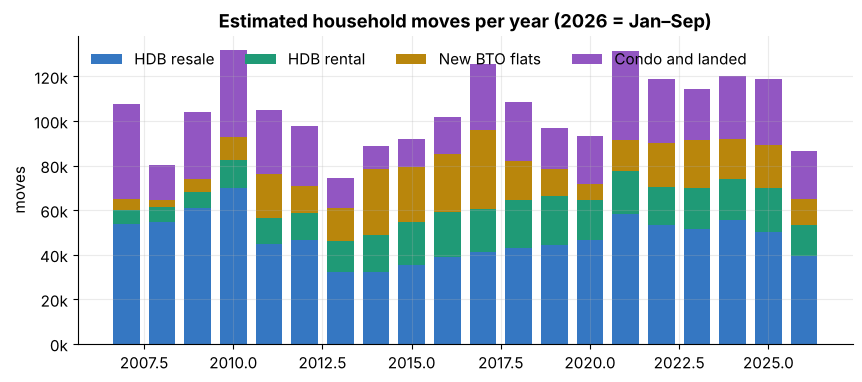

2025 shares: {'res': 0.423, 'rent': 0.165, 'bto': 0.165, 'priv': 0.247}


In [8]:
fig, ax = plt.subplots()
bottom = np.zeros(len(moves))
for k, lab, c in [('res', 'HDB resale', C3), ('rent', 'HDB rental', C1), ('bto', 'New BTO flats', C4), ('priv', 'Condo and landed', C5)]:
    ax.bar(moves.index, moves[k], bottom=bottom, color=c, label=lab, width=0.75); bottom += moves[k].values
ax.set_title('Estimated household moves per year (2026 = Jan–Sep)'); ax.set_ylabel('moves'); ax.legend(ncol=4, frameon=False, loc='upper left')
ax.yaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}k'); plt.show()
print('2025 shares:', (moves.loc[2025, ['res', 'rent', 'bto', 'priv']] / moves.loc[2025, 'total']).round(3).to_dict())

**Reading it.** HDB resales are the biggest and steadiest source of moves (about 40% in 2025). Condo and landed moves swing the most (2007 boom, 2008 crash, 2013 cooling measures). BTO completions arrive in lumps. Rental moves rose steadily until Covid.

## 3. Why moves happen: the MOP wave
Owners must live in a new flat for 5 years (the Minimum Occupation Period) before selling. So **resale chances depend on the flat's age**. For every lease-start cohort we divide its resales in a year by the flats completed that year, then take the median across cohorts (cohorts under 3,000 flats are too noisy and skipped).

36 years of data show **two eras**: since the 2010–2013 cooling measures and rule changes, mature flats are resold noticeably less often. So the forecast uses the post-2011 rates.

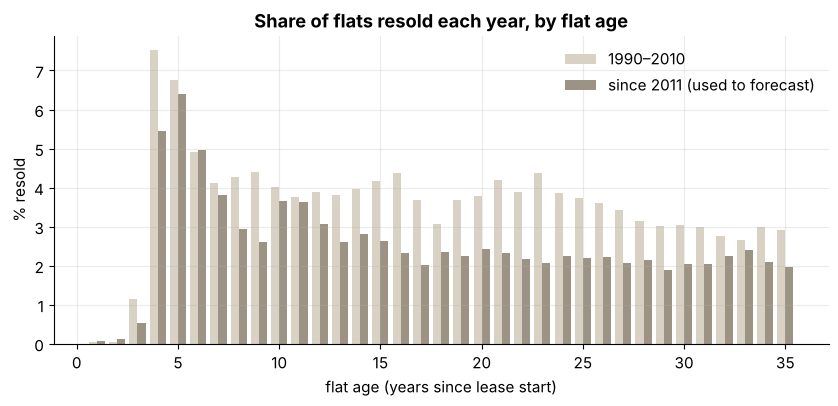

mature flats (age 10-30): 3.74% a year before 2011 vs 2.44% since -> 35% less often


,flats reaching MOP (completed 5 yrs earlier),OrangeTee forecast
2025,"7,314","6,973"
2026,"13,756","13,484"
2027,"20,064","18,939"
2028,"21,393","21,393"
2029,"18,011",–
2030,"19,587",–
2031,"11,829",–


In [9]:
def hazard_table(y0, y1):
    hz = {}
    for L, row in D['cohorts'].items():
        u = U.get(int(L), 0)
        if u < 3000: continue
        for y, n in row.items():
            y = int(y)
            if y0 <= y <= y1: hz.setdefault(y - int(L), []).append(n * (12 / 9 if y == 2026 else 1) / u)
    return {a: float(np.median(v)) for a, v in hz.items()}

def hazard_fn(H):
    tail = np.mean([H[a] for a in H if 20 <= a <= 35])           # beyond 35 years: average of ages 20-35
    return lambda a: 0.0 if a < 1 else (H[a] if a <= 35 and a in H else tail)

h1, hNow, hTrain = hazard_fn(hazard_table(1990, 2010)), hazard_fn(hazard_table(2011, 2026)), hazard_fn(hazard_table(2011, 2023))

def E(y, Ufut=20000, h=None):
    """Structural expected resales in year y = sum over completion years of flats x h(age)."""
    h = h or hNow; s = 0.0
    for c in range(1930, y + 1):
        u = U.get(c, 0) if c <= 2025 else (max(U.get(2026, 0), Ufut) if c == 2026 else Ufut)
        s += u * h(y - c)
    return s

ages = np.arange(1, 36)
fig, ax = plt.subplots()
ax.bar(ages - 0.2, [h1(a) * 100 for a in ages], 0.4, color='#D9D1C3', label='1990–2010')
ax.bar(ages + 0.2, [hNow(a) * 100 for a in ages], 0.4, color=GREY, label='since 2011 (used to forecast)')
ax.set_title('Share of flats resold each year, by flat age'); ax.set_xlabel('flat age (years since lease start)'); ax.set_ylabel('% resold'); ax.legend(frameon=False); plt.show()
mature = lambda h: np.mean([h(a) for a in range(10, 31)])
print(f'mature flats (age 10-30): {mature(h1):.2%} a year before 2011 vs {mature(hNow):.2%} since -> {1 - mature(hNow) / mature(h1):.0%} less often')
mop = pd.DataFrame({'flats reaching MOP (completed 5 yrs earlier)': {y: U.get(y - 5, 0) for y in range(2025, 2032)}})
mop['OrangeTee forecast'] = pd.Series({2025: 6973, 2026: 13484, 2027: 18939, 2028: 21393}).astype('Int64')
mop.style.format('{:,}', na_rep='–')

Our MOP counts match OrangeTee's published research (HDB Market Outlook 2026), a check that the block data is read correctly. The MOP wave roughly triples from 2025 to 2028.

## 4. Demand model: structure × season × market mood
$$\text{resales}_{\text{month}} = \frac{E(y)}{12}\times S_{\text{month}}\times M_y$$
* $E(y)$: structural resales from the flat stock and resale chances by age (above)
* $S$: seasonal index (Chinese New Year dip, mid-year peak), fitted on 2011–2023
* $M_y$: **market mood**, how hot the market is that year relative to the structure (1 = normal)

Apr–May 2020 (Covid circuit breaker) are excluded from fitting.

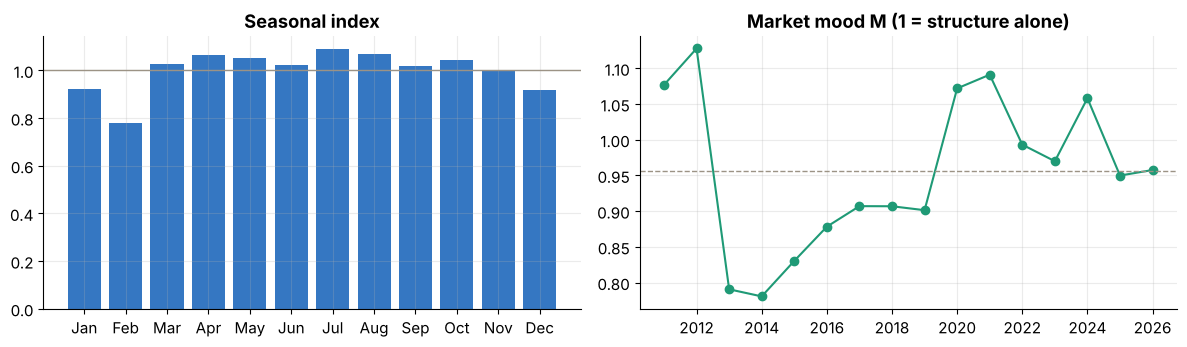

monthly noise sd 0.107 | market mood AR(1): mean 0.956, persistence 0.463, shock sd 0.095
structural resales: 2026 27,202  ->  2031 29,750


In [10]:
covid = (yrL == 2020) & np.isin(moL, [3, 4])
train = (yrL >= 2011) & (yrL <= 2023)
yearsNow = list(range(2011, 2027))
baseT = np.array([E(y, 20000, hTrain) / 12 for y in yrL]); ratioT = natL / baseT
def mood_of(S, ratio):
    return {y: np.mean(ratio[(yrL == y) & ~covid] / S[moL[(yrL == y) & ~covid]]) for y in yearsNow}
S = np.array([ratioT[train & (moL == m) & ~covid].mean() for m in range(12)])
MT = mood_of(S, ratioT)
S = S / S.mean() * np.mean([MT[y] for y in yearsNow if y <= 2023])   # the average level lives in the seasonal index
MT = mood_of(S, ratioT)
fitted = np.where(train, baseT * S[moL] * np.array([MT.get(y, np.nan) for y in yrL]), np.nan)
epsSd = np.std(np.log(natL[train & ~covid] / fitted[train & ~covid]))

def ar1(ms):
    ms = np.asarray(ms, float); mu = ms.mean()
    if len(ms) < 4: return mu, 0.5, 0.1
    phi = np.corrcoef(ms[:-1] - mu, ms[1:] - mu)[0, 1]
    return mu, phi, np.std(ms[1:] - mu - phi * (ms[:-1] - mu), ddof=1)

baseF = np.array([E(y, 20000, hNow) / 12 for y in yrL])
M = mood_of(S, natL / baseF)                         # market mood by year under today's resale chances
mu, phi, sdM = ar1([M[y] for y in yearsNow])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.bar(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], S / S.mean(), color=C3); a1.axhline(1, color=GREY, lw=1); a1.set_title('Seasonal index')
a2.plot(list(M), list(M.values()), 'o-', color=C1); a2.axhline(mu, color=GREY, ls='--', lw=1); a2.set_title('Market mood M (1 = structure alone)')
plt.tight_layout(); plt.show()
print(f'monthly noise sd {epsSd:.3f} | market mood AR(1): mean {mu:.3f}, persistence {phi:.3f}, shock sd {sdM:.3f}')
print(f'structural resales: 2026 {E(2026):,.0f}  ->  2031 {E(2031):,.0f}')

## 5. Forecast check
**Monthly hold-out.** Fit on 2011–2023 only, then forecast every month Jan 2024 – Sep 2026 without peeking. The fair baseline repeats 2023 month by month (the only information available at end-2023).

**Rolling 1–5 year backtest.** For each start year 2013–2021, refit resale chances and market mood with data up to that year only, forecast the next 1–5 annual totals, and compare with what happened.

,MAE,RMSE,MAPE
our model,241,325,11.8%
fair baseline (2023 repeated),271,344,12.9%
same month last year (peeks),232,311,11.1%


,tests,our model,repeat last year
years ahead,,,
1,9,5.8%,7.2%
2,9,6.8%,12.7%
3,9,7.6%,15.3%
4,9,7.2%,19.8%
5,8,8.3%,22.1%


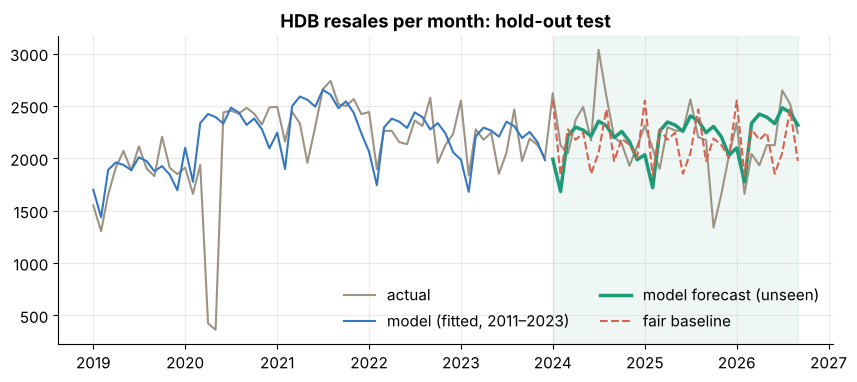

In [11]:
test = yrL >= 2024
pred = np.where(test, baseT * S[moL] * MT[2023], np.nan)
fair = np.array([natL[(2023 - 1990) * 12 + m] for m in moL])
lag = np.concatenate([np.full(12, np.nan), natL[:-12]])
def metrics(p):
    e = natL[test] - p[test]
    return dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()), MAPE=np.mean(np.abs(e) / natL[test]))
bt = pd.DataFrame({'our model': metrics(pred), 'fair baseline (2023 repeated)': metrics(fair), 'same month last year (peeks)': metrics(lag)}).T
display(bt.style.format({'MAE': '{:.0f}', 'RMSE': '{:.0f}', 'MAPE': '{:.1%}'}))

roll = {k: ([], []) for k in range(1, 6)}
for T in range(2013, 2022):
    hT = hazard_fn(hazard_table(2011, T))
    Ms = [annual(y) / E(y, 20000, hT) for y in range(2011, T + 1)]
    m_, p_, _ = ar1(Ms)
    for k in range(1, 6):
        y = T + k
        if y > 2025: break
        pm = E(y, 20000, hT) * (m_ + p_ ** k * (Ms[-1] - m_)); act = annual(y)
        roll[k][0].append(abs(pm - act) / act); roll[k][1].append(abs(annual(T) - act) / act)
rollT = pd.DataFrame({'tests': [len(roll[k][0]) for k in roll], 'our model': [np.mean(roll[k][0]) for k in roll],
                      'repeat last year': [np.mean(roll[k][1]) for k in roll]}, index=pd.Index(range(1, 6), name='years ahead'))
display(rollT.style.format({'our model': '{:.1%}', 'repeat last year': '{:.1%}'}))

idx = pd.period_range('1990-01', periods=NL, freq='M').to_timestamp(); w = yrL >= 2019
fig, ax = plt.subplots()
ax.plot(idx[w], natL[w], color=GREY, lw=1.5, label='actual')
ax.plot(idx[w & train], fitted[w & train], color=C3, lw=1.5, label='model (fitted, 2011–2023)')
ax.plot(idx[test], pred[test], color=C1, lw=2.5, label='model forecast (unseen)')
ax.plot(idx[test], fair[test], color=C2, lw=1.5, ls='--', label='fair baseline')
ax.axvspan(idx[test][0], idx[-1], color=C1, alpha=0.07); ax.set_title('HDB resales per month: hold-out test'); ax.legend(frameon=False, ncol=2); plt.show()

**Reading it.** On unseen months the model beats the fair baseline on every metric. The bigger win is long range: five years ahead its error stays around 8%, against about 22% for "repeat last year". It works because most future resales come from flats that are already built and whose MOP year is known.

### 5b. Are the uncertainty bands honest? (prediction-interval coverage)
A forecast band is only useful if reality lands inside it as often as it claims. We roll back to each start year 2013–2021, simulate 4,000 futures of annual HDB resales using only data up to that year (the same structure × AR(1) market mood, plus monthly noise), and record where the actual outcome fell. A well-calibrated 80% band should contain the truth about 80% of the time, and a 50% band about half the time.

,tests,inside_80pct_band,inside_50pct_band
horizon,,,
1,9,89%,78%
2,9,89%,67%
3,9,89%,44%
4,9,89%,67%
5,8,88%,50%
all,44,89%,61%


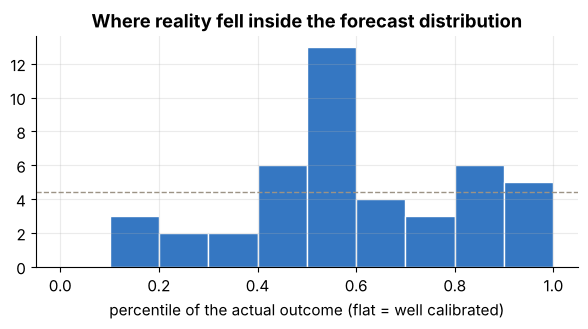

In [12]:
rng_cov = np.random.default_rng(2027)
cov = []
for T in range(2013, 2022):
    hT = hazard_fn(hazard_table(2011, T))
    Ms = [annual(y) / E(y, 20000, hT) for y in range(2011, T + 1)]
    m_, p_, s_ = ar1(Ms)
    paths = np.empty((4000, 5)); m = np.full(4000, Ms[-1])
    for k in range(5):
        m = m_ + p_ * (m - m_) + rng_cov.normal(0, s_, 4000)
        paths[:, k] = m * np.exp(rng_cov.normal(0, epsSd / math.sqrt(12), 4000))   # 12 months of noise, summed
    for k in range(1, 6):
        y = T + k
        if y > 2025: break
        sims = paths[:, k - 1] * E(y, 20000, hT); act = annual(y)
        q = (sims < act).mean()                                    # where reality fell in the simulated distribution
        cov.append(dict(start=T, horizon=k, actual=act, p10=np.quantile(sims, 0.1), p90=np.quantile(sims, 0.9),
                        in80=0.1 <= q <= 0.9, in50=0.25 <= q <= 0.75, pit=q))
cov = pd.DataFrame(cov)
covT = cov.groupby('horizon').agg(tests=('in80', 'size'), inside_80pct_band=('in80', 'mean'), inside_50pct_band=('in50', 'mean'))
covT.loc['all'] = [len(cov), cov.in80.mean(), cov.in50.mean()]
display(covT.style.format({'inside_80pct_band': '{:.0%}', 'inside_50pct_band': '{:.0%}', 'tests': '{:.0f}'}))
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(cov.pit, bins=np.linspace(0, 1, 11), color=C3, edgecolor='w'); ax.axhline(len(cov) / 10, color=GREY, ls='--', lw=1)
ax.set_title('Where reality fell inside the forecast distribution'); ax.set_xlabel('percentile of the actual outcome (flat = well calibrated)'); plt.show()

**Reading it.** About 89% of actual outcomes fell inside the 80% band and about 61% inside the 50% band, so the bands are a little **wider than they need to be**: the forecast is cautious, not overconfident. For a risk analysis that is the safer error, since the risk floors will tend to overstate rather than understate the downside. The sample is small (44 overlapping tests from nine start years), so we read this as "roughly calibrated, slightly conservative" rather than tuning the bands to it.

## 6. Town clusters and depots
Five features per HDB town, standardised (z-scores): **resold** (resales in the last 12 months / flats), **growth** (resales Oct 2023–Sep 2026 vs 2017–2019), **mopSoon** (flats completed 2021–2026 / all flats), **rented** (rental approvals last 12 months / flats), **big** (share of 4-room+ resales). k-means with k-means++ starts, best of 8. Depots: a second, weighted k-means on town coordinates, weighted by each town's estimated moves.

The random generator below (mulberry32 with a polar Box-Muller normal) is the same one the app uses, so clusters and simulations match the app exactly.

silhouette by k: {2: 0.313, 3: 0.325, 4: 0.329, 5: 0.293, 6: 0.256}


,resold,growth,mopSoon,rented,big,jobs,towns
cluster,,,,,,,
Family-size flats,2.200,12.600,5.400,3.000,84.800,"2,898.600",10
Fast-growing,2.800,81.400,7.000,3.100,76.800,"2,866.800",2
MOP wave coming,2.200,33.200,17.100,2.900,67.500,"3,489.400",4
Rental hotspots,1.800,10.700,3.100,4.100,57.300,"1,913.000",10


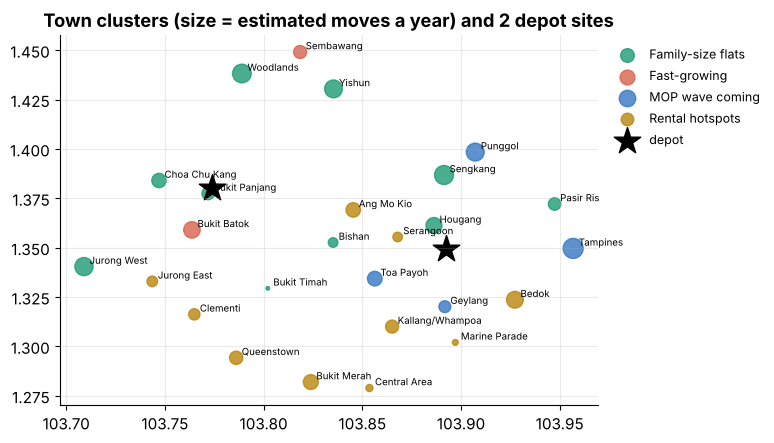

In [13]:
class Rng:
    """mulberry32 + polar Box-Muller: identical stream to the app's makeRng(seed)."""
    def __init__(self, seed): self.a = seed & 0xFFFFFFFF; self.spare = None
    @staticmethod
    def _imul(x, y): return (x * y) & 0xFFFFFFFF
    def u(self):
        self.a = (self.a + 0x6D2B79F5) & 0xFFFFFFFF; a = self.a
        t = self._imul(a ^ (a >> 15), 1 | a)
        t = ((t + self._imul(t ^ (t >> 7), 61 | t)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    def normal(self, mu=0.0, sd=1.0):
        if self.spare is not None: s, self.spare = self.spare, None; return mu + sd * s
        while True:
            x = self.u() * 2 - 1; y = self.u() * 2 - 1; r = x * x + y * y
            if 0 < r < 1: break
        f = math.sqrt(-2 * math.log(r) / r); self.spare = y * f; return mu + sd * x * f
    def tri(self, a, c, b):
        x = self.u(); F = (c - a) / (b - a)
        return a + math.sqrt(x * (b - a) * (c - a)) if x < F else b - math.sqrt((1 - x) * (b - a) * (b - c))

rows = []
for t in TOWNS.itertuples():
    units = sum(D['blocks'][t.code].values()); r = np.array(D['resale'][t.name][:NFULL])
    rt = np.array(D['rental']['CENTRAL' if t.name == 'CENTRAL AREA' else t.name]); ft = D['flatTypes'][t.name]
    big = sum(ft.get(k, 0) for k in ['4 ROOM', '5 ROOM', 'EXECUTIVE', 'MULTI-GENERATION'])
    comp = sum(D['blocks'][t.code].get(str(y), 0) for y in range(2021, 2027))
    rows.append(dict(name=t.name, resold=r[-12:].sum() / units * 100, growth=(r[-36:].sum() / r[:36].sum() - 1) * 100,
                     mopSoon=comp / units * 100, rented=rt[-12:].sum() / units * 100, big=big / sum(ft.values()) * 100,
                     jobs=2 * r[-12:].sum() + rt[-12:].sum() * NEW_TENANCY, lat=t.lat, lon=t.lon))
towns = pd.DataFrame(rows).set_index('name'); FEATS = ['resold', 'growth', 'mopSoon', 'rented', 'big']
X = ((towns[FEATS] - towns[FEATS].mean()) / towns[FEATS].std(ddof=0)).values

def kmeans(X, k, seed, w=None):
    rng, n = Rng(seed), len(X); w = np.ones(n) if w is None else np.asarray(w, float)
    d2 = lambda a, b: float(((a - b) ** 2).sum())
    C = [X[int(rng.u() * n)].copy()]
    while len(C) < k:                                   # k-means++ seeding
        dist = [min(d2(x, c) for c in C) for x in X]; r = rng.u() * sum(dist); i = 0
        while r > dist[i]: r -= dist[i]; i += 1
        C.append(X[min(i, n - 1)].copy())
    lab = [-1] * n
    for _ in range(50):                                 # Lloyd iterations
        nl = [int(np.argmin([d2(x, c) for c in C])) for x in X]
        same = nl == lab; lab = nl
        if same: break
        for j in range(k):
            m = [i for i in range(n) if lab[i] == j]
            if m: C[j] = (X[m] * w[m, None]).sum(0) / w[m].sum()
    return np.array(lab), np.array(C), sum(d2(X[i], C[lab[i]]) * w[i] for i in range(n))
def best_kmeans(X, k, w=None):
    return min((kmeans(X, k, 100 + s, w) for s in range(1, 9)), key=lambda r: r[2])
def silhouette(X, lab):
    out = []
    for i, x in enumerate(X):
        own = [X[j] for j in range(len(X)) if j != i and lab[j] == lab[i]]
        if not own: out.append(0); continue
        a = np.mean([np.linalg.norm(x - y) for y in own])
        b = min(np.mean([np.linalg.norm(x - X[j]) for j in range(len(X)) if lab[j] == c]) for c in set(lab) if c != lab[i])
        out.append((b - a) / max(a, b))
    return float(np.mean(out))
NAMES = {'resold': 'High churn', 'growth': 'Fast-growing', 'mopSoon': 'MOP wave coming', 'rented': 'Rental hotspots', 'big': 'Family-size flats'}
def name_clusters(C):
    used, out = set(), []
    for c in C:
        order = sorted(zip(FEATS, c), key=lambda z: -z[1])
        if order[0][1] < 0.35: out.append('Steady mature'); continue
        pick = next(((f, v) for f, v in order if v >= 0.35 and f not in used), order[0]); used.add(pick[0]); out.append(NAMES[pick[0]])
    return out

sil = {k: silhouette(X, best_kmeans(X, k)[0]) for k in range(2, 7)}
lab, C, inertia = best_kmeans(X, 4); names = name_clusters(C)
towns['cluster'] = [names[l] for l in lab]
print('silhouette by k:', {k: round(v, 3) for k, v in sil.items()})
display(towns.groupby('cluster')[FEATS + ['jobs']].mean().round(1).assign(towns=towns.groupby('cluster').size()))
geo = np.c_[towns.lon * math.cos(1.35 * math.pi / 180), towns.lat]
dlab, dC, _ = best_kmeans(geo, 2, towns.jobs.values)
fig, ax = plt.subplots(figsize=(9, 4.8))
cols = dict(zip(sorted(set(names)), [C1, C2, C3, C4, C5]))
for nm, g in towns.groupby('cluster'): ax.scatter(g.lon, g.lat, s=g.jobs / 25, color=cols[nm], alpha=0.8, label=nm)
ax.scatter(dC[:, 0] / math.cos(1.35 * math.pi / 180), dC[:, 1], marker='*', s=400, color='k', label='depot')
for n_, r_ in towns.iterrows(): ax.annotate(n_.title(), (r_.lon, r_.lat), fontsize=7, xytext=(4, 2), textcoords='offset points')
ax.set_title('Town clusters (size = estimated moves a year) and 2 depot sites'); ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.01, 1)); ax.set_aspect('equal'); plt.show()

## 7. Global and policy indicators
Does the market mood respond to **recessions** and to **rule changes** (who may buy, how much they can borrow)? We line up 36 years of mood (each year measured against its own era's resale chances) with:
* **Recession years**: real GDP growth under 1% (1998, 2001, 2009, 2020; SingStat).
* **Policy impulse**: 16 dated changes, +1 = demand opened up (e.g. 1989 resale opened to PRs; July 2026 wait-out removed), −1 = restricted (e.g. 2013 three-year wait for new PRs, ABSD rises, loan-limit cuts). A change in month m counts (13 − m)/12 in its own year and the rest the next year.

$$\log M_y = a + b\,\text{era2011}_y + \phi\log M_{y-1} + \beta_{rec}\,\text{recession}_y + \beta_{pol}\,\text{impulse}_y$$

recession year: +16.6% resales | one major rule change: +6.5% (post-2011 alone +15.3%)
mood explained (R2): 64.7% without indicators -> 69.2% with | GDP growth coefficient instead of recession flag: -0.0041 per % (≈ nothing)


,bRec,bPol
dropped recession,,
1998,+6.9%,+3.5%
2001,+18.9%,+6.6%
2009,+20.8%,+7.7%
2020,+24.1%,+6.5%


government leans against the wind: after a hot year 8/8 changes were tightenings; after a quiet year 3/7


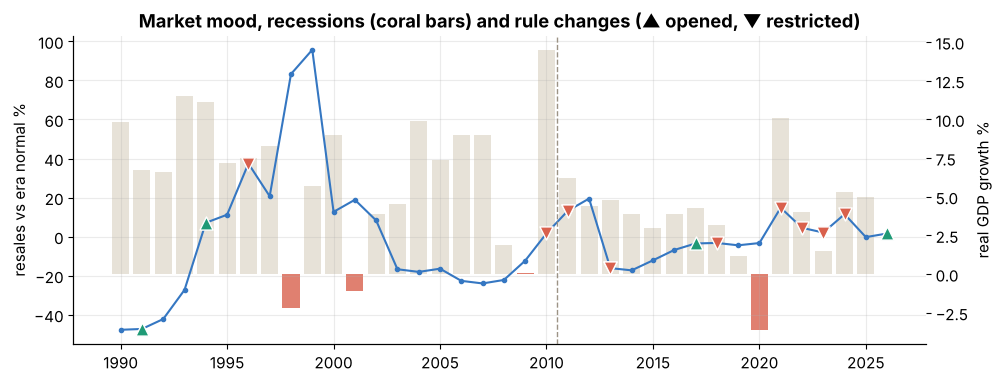

In [14]:
GDP = {int(k): v for k, v in D['gdp'].items()}            # real GDP growth, % (SingStat)
POL = [  # (year, month, step, what changed): +1 = demand opened up, -1 = restricted; 1 = major, 0.5 = minor / mostly private
    (1989,  8, +1.0, "Resale opened to PRs and private-home owners; income ceiling removed"),
    (1991,  9, +0.5, "PRs need only HDB approval; singles aged 35+ may buy resale"),
    (1994,  1, +0.5, "CPF Housing Grant extended to resale buyers"),
    (1996,  5, -1.0, "First anti-speculation package"),
    (2010,  2, -0.5, "Seller stamp duty introduced; LTV cut to 80%"),
    (2011,  1, -0.5, "Seller stamp duty raised; LTV 60% on a second loan"),
    (2011, 12, -0.5, "ABSD introduced (foreigners 10%, PRs 3% on 2nd home)"),
    (2013,  1, -1.0, "ABSD raised; 30% mortgage servicing ratio on HDB loans"),
    (2013,  8, -1.0, "New PRs must wait 3 years to buy resale; HDB loans capped at 25 years"),
    (2017,  3, +0.5, "Seller stamp duty cut; TDSR eased"),
    (2018,  7, -0.5, "ABSD raised"),
    (2021, 12, -1.0, "HDB loan LTV 85%; TDSR 55%; foreigner ABSD 30%"),
    (2022,  9, -1.0, "15-month wait-out for private-home owners; HDB LTV 80%; 3% rate floor"),
    (2023,  4, -0.5, "Foreigner ABSD doubled to 60%"),
    (2024,  8, -0.5, "HDB loan LTV 75% (grants raised)"),
    (2026,  7, +1.0, "15-month wait-out removed as resale prices ease"),
]
def impulse(y, steps=POL):
    s = 0.0
    for Y, m, v, _ in steps:
        f = (13 - m) / 12
        if Y == y: s += v * f
        if Y == y - 1: s += v * (1 - f)
    return s
rec = lambda y: 1.0 if GDP.get(y, 99) < 1 else 0.0
Mlong = {y: annual(y) / E(y, 20000, h1 if y <= 2010 else hNow) for y in range(1990, 2027)}
Lm = lambda y: math.log(Mlong[y])
hist = list(range(1991, 2026))
def ols(Xr, y):
    Xr, y = np.asarray(Xr, float), np.asarray(y, float); b = np.linalg.solve(Xr.T @ Xr, Xr.T @ y); res = y - Xr @ b
    return b, 1 - (res ** 2).sum() / ((y - y.mean()) ** 2).sum(), math.sqrt((res ** 2).sum() / (len(y) - Xr.shape[1]))
design = lambda ys, ind: [[1, float(y >= 2011), Lm(y - 1)] + ([rec(y), impulse(y)] if ind else []) for y in ys]
bInd, r2Ind, _ = ols(design(hist, True), [Lm(y) for y in hist]); _, r2Plain, _ = ols(design(hist, False), [Lm(y) for y in hist])
bRec, bPol = bInd[3], bInd[4]
recYears = [y for y in hist if rec(y)]
loo = pd.DataFrame([(r, *ols(design(ys, True), [Lm(y) for y in ys])[0][3:5]) for r in recYears
                    for ys in [[y for y in hist if y not in (r, r + 1)]]], columns=['dropped recession', 'bRec', 'bPol']).set_index('dropped recession')
ys11 = [y for y in hist if y >= 2011]
bPol11 = ols([[1, Lm(y - 1), rec(y), impulse(y)] for y in ys11], [Lm(y) for y in ys11])[0][3]
bGdp = ols([[1, float(y >= 2011), Lm(y - 1), GDP[y], impulse(y)] for y in hist], [Lm(y) for y in hist])[0][3]
print(f'recession year: {math.exp(bRec) - 1:+.1%} resales | one major rule change: {math.exp(bPol) - 1:+.1%} (post-2011 alone {math.exp(bPol11) - 1:+.1%})')
print(f'mood explained (R2): {r2Plain:.1%} without indicators -> {r2Ind:.1%} with | GDP growth coefficient instead of recession flag: {bGdp:+.4f} per % (≈ nothing)')
display((np.exp(loo) - 1).style.format('{:+.1%}').set_caption('Robustness: drop each recession and refit'))

eraMean = lambda y: np.mean([Mlong[k] for k in Mlong if (k <= 2010) == (y <= 2010)])
tH = nH = tC = nC = 0
for Y, _, v, _ in POL:
    p = Y - 1
    if p not in Mlong: continue
    if Mlong[p] > eraMean(p): nH += 1; tH += v < 0
    else: nC += 1; tC += v < 0
print(f'government leans against the wind: after a hot year {tH}/{nH} changes were tightenings; after a quiet year {tC}/{nC}')

yrs = np.arange(1990, 2027); mood = [(Mlong[y] / eraMean(y) - 1) * 100 for y in yrs]
fig, ax = plt.subplots(figsize=(11, 4)); ax2 = ax.twinx()
ax2.bar(yrs, [GDP.get(y, np.nan) for y in yrs], color=[C2 if rec(y) else '#E2DBCF' for y in yrs], alpha=0.8, zorder=0); ax2.set_ylabel('real GDP growth %'); ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.plot(yrs, mood, 'o-', color=C3, ms=3, label='market mood (vs era normal)')
for Y, m, v, _ in POL:
    if Y >= 1990: ax.scatter(Y, mood[Y - 1990], marker='^' if v > 0 else 'v', s=90, color=C1 if v > 0 else C2, zorder=5, edgecolor='w')
ax.axvline(2010.5, color=GREY, ls='--', lw=1); ax.set_ylabel('resales vs era normal %'); ax.set_title('Market mood, recessions (coral bars) and rule changes (▲ opened, ▼ restricted)'); plt.show()

**Findings.**
* **Recessions raise HDB resales** (about +17% in a recession year, positive whichever recession is dropped). Likely reason: households sell to downsize or free cash, and softer prices bring buyers in. For a mover, a recession lifts volume but probably squeezes prices, so the simulation also cuts our price in recession years (an assumption).
* **Rule changes push the expected way** (about ±7% per major change, fading over the next years; about 15% using post-2011 years alone).
* **GDP growth itself adds nothing** once recessions are flagged.
* Indicators explain the past, but nobody knows future GDP, so the forecast uses them as **scenarios**: shocks strike at random as often as history suggests, or are forced in a chosen year for stress tests.

For the forecast the two effects are held fixed and the mood dynamics are refitted on today's era (2011–2026) after removing them, so the shocks are not counted twice.

In [15]:
ysF = yearsNow[1:]
cF, phiF, sdF = (lambda r: (r[0][0], r[0][1], r[2]))(ols([[1, math.log(M[y - 1])] for y in ysF],
                [math.log(M[y]) - bRec * rec(y) - bPol * impulse(y) for y in ysF]))
DYN = dict(c=cF, phi=phiF, sd=sdF, bRec=bRec, bPol=bPol, muLog=cF / (1 - phiF),
           pRec=len(recYears) / len(hist), pStep=len(POL) / (2026 - 1989 + 1),
           pTightHot=(tH + 1) / (nH + 2), pTightCool=(tC + 1) / (nC + 2),
           pBig=sum(abs(p[2]) == 1 for p in POL) / len(POL), carry2027=impulse(2027))
pd.Series(DYN).to_frame('forecast mood dynamics')

,forecast mood dynamics
c,-0.015
phi,0.656
sd,0.080
bRec,0.154
bPol,0.063
muLog,-0.044
pRec,0.114
pStep,0.421
pTightHot,0.900
pTightCool,0.444


## 8. Five-year Monte Carlo of market demand (2027–2031)
One simulated future = 60 months of demand. Sources of uncertainty:
* **market mood**: the AR(1) above, plus random recessions and rule changes (or forced ones)
* **monthly noise** (lognormal, sd from the fit), **rentals** (±6%), **BTO completions** (±15% a year around 20,000), **private moves** (sd from URA 2023–26, follow rule changes)
* **our market share**: triangular(0.5×, 1×, 1.3× the 3% target), S-curve ramp over 24 months; **price** random walk (3% a year); **capacity** noise (±3%)

The same 2,000 futures (seed 2027) are fed to every strategy (common random numbers), so differences between strategies are not luck.

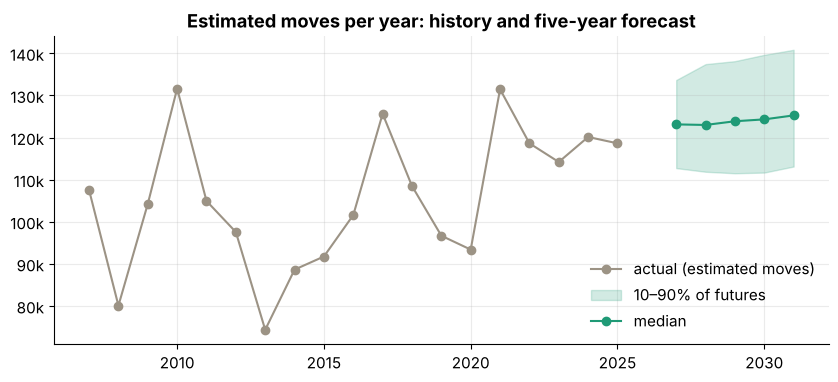

,0.100,0.500,0.900
2027,"112,734.000","123,121.000","133,656.000"
2028,"111,870.000","122,985.000","137,432.000"
2029,"111,511.000","123,866.000","138,138.000"
2030,"111,676.000","124,312.000","139,641.000"
2031,"113,113.000","125,253.000","140,839.000"


In [16]:
BASE = dict(shareTarget=0.03, rampMonths=24, priceHDB=900, crewCost=11000, jobsPerCrew=30, subFrac=0.80, truckCapex=125000,
            btoFuture=20000, newTenancy=0.50, disc=0.10, recMode='random', recYear=2028, recPriceHit=0.10, polMode='random', polYear=2028)
FIXED = dict(shareStart=0.005, varCost=90, truckLife=10, truckRun=1500, truckLease=2900, overhead=30000, marketing=0.06, downtime=0.05,
             subCap=0.25, brokerShare=0.70, brokerFrac=0.85, brokerCap=0.85, nsim=2000, seed=2027, H=60)
Sr = np.array([rent[np.arange(len(rent)) % 12 == m].mean() for m in range(12)]); Sr /= Sr.mean(); rentLevel = rent.mean()
recent = np.array([m for _, m in privQ[-15:]]); privLevel, privSd = recent.mean(), recent.std() / recent.mean()

def gen_scenarios(a, nsim=FIXED['nsim'], seed=FIXED['seed']):
    rng, H, d = Rng(seed), FIXED['H'], DYN
    Ey = [E(2027 + k, a['btoFuture']) for k in range(5)]
    ramp = 1 / (1 + np.exp(-(np.arange(H) - a['rampMonths'] / 2) / (a['rampMonths'] / 8)))
    out = {k: np.zeros((nsim, H)) for k in ['res', 'rent', 'bto', 'priv', 'share', 'drift', 'capNoise']}
    for s in range(nsim):
        Mk, PM, recY, imp = [], [], [], [d['carry2027'], 0, 0, 0, 0, 0]; x = math.log(M[2026])
        for k in range(5):
            year = 2027 + k; uR, uS, uD, uZ, uM = rng.u(), rng.u(), rng.u(), rng.u(), rng.u(); e = rng.normal(0, d['sd'])
            r_ = (uR < d['pRec']) if a['recMode'] == 'random' else (year == a['recYear']) if a['recMode'] == 'stress' else False
            step, f = 0.0, 0.5
            if a['polMode'] == 'random' and uS < d['pStep']:
                tight = uD < (d['pTightHot'] if x > d['muLog'] else d['pTightCool'])
                step = (-1 if tight else 1) * (1 if uZ < d['pBig'] else 0.5); f = (12 - math.floor(uM * 12)) / 12
            elif a['polMode'] in ('loosen', 'tighten') and year == a['polYear']: step = 1.0 if a['polMode'] == 'loosen' else -1.0
            imp[k] += step * f; imp[k + 1] += step * (1 - f)
            x = d['c'] + d['phi'] * x + d['bRec'] * r_ + d['bPol'] * imp[k] + e
            Mk.append(math.exp(x)); recY.append(r_); PM.append(math.exp(x - d['bRec'] * r_ - d['muLog']))
        btoY = [a['btoFuture'] / 12 * math.exp(rng.normal(0, 0.15)) for _ in range(5)]
        shareT = rng.tri(0.5 * a['shareTarget'], a['shareTarget'], 1.3 * a['shareTarget']); dr = 0.0
        for t in range(H):
            k, mon = t // 12, t % 12
            out['res'][s, t] = 2 * Ey[k] / 12 * S[mon] * Mk[k] * math.exp(rng.normal(0, epsSd))
            out['rent'][s, t] = rentLevel * Sr[mon] * math.exp(rng.normal(0, 0.06)) * a['newTenancy']
            out['bto'][s, t] = btoY[k]
            out['priv'][s, t] = privLevel * math.exp(rng.normal(0, privSd)) * PM[k]
            out['share'][s, t] = FIXED['shareStart'] + (shareT - FIXED['shareStart']) * ramp[t]
            dr += rng.normal(0, 0.03 / math.sqrt(12)); out['drift'][s, t] = math.exp(dr) * ((1 - a['recPriceHit']) if recY[k] else 1)
            out['capNoise'][s, t] = math.exp(rng.normal(0, 0.03))
    return out

SC = gen_scenarios(BASE)
market = (SC['res'] + SC['rent'] + SC['bto'] + SC['priv']).reshape(-1, 5, 12).sum(2)
fan = pd.DataFrame({q: np.quantile(market, q, axis=0) for q in (0.1, 0.5, 0.9)}, index=range(2027, 2032))
fig, ax = plt.subplots()
ax.plot(moves.index[:-1], moves.total[:-1], 'o-', color=GREY, label='actual (estimated moves)')
ax.fill_between(fan.index, fan[0.1], fan[0.9], color=C1, alpha=0.2, label='10–90% of futures'); ax.plot(fan.index, fan[0.5], 'o-', color=C1, label='median')
ax.set_title('Estimated moves per year: history and five-year forecast'); ax.yaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}k'); ax.legend(frameon=False); plt.show()
fan.round(0)

## 9. Fleet sizing, strategies, risk and return
**Newsvendor.** An idle crew-slot costs its wages, truck depreciation and running cost (overage $C_o$); a job above capacity goes to a subcontractor at a premium (underage $C_u$). Own capacity up to the critical-ratio quantile of monthly demand: $CR = C_u/(C_u + C_o)$.

**Four ways to build the fleet** (the risk responses to the fixed-asset problem): buy the whole fleet upfront (sized for year 3), lease and resize yearly, **phased buying** (buy only what each year needs, never sell), and an asset-light broker (no trucks, everything subcontracted). Subcontractors absorb overflow up to 25% of demand.

Cu = S$630, Co = S$451  ->  critical ratio 58.3%: own capacity for that quantile of monthly demand


,mean NPV,chance of loss,worst 5% avg (CVaR),cash needed,IRR,trucks 2027→2031
Buy fleet upfront,"−S$1,097,588",81%,"−S$3,720,323","S$4,160,943",-5.5%,11→11
Lease and resize yearly,"−S$246,884",51%,"−S$2,753,573","S$3,092,545",-21.2%,3→11
Phased buying,"S$208,100",37%,"−S$2,298,589","S$2,832,739",15.2%,3→11
Asset-light broker,"−S$338,817",100%,"−S$523,338","S$614,124",nan%,0→0


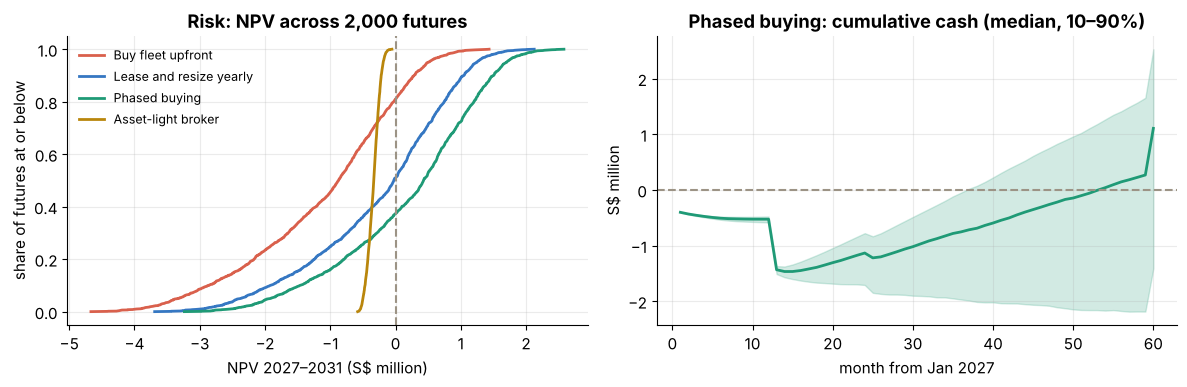

In [17]:
def newsvendor(a):
    Co = (a['crewCost'] + a['truckCapex'] / FIXED['truckLife'] / 12 + FIXED['truckRun']) / a['jobsPerCrew']
    Cu = a['subFrac'] * a['priceHDB'] - FIXED['varCost']
    return dict(Co=Co, Cu=Cu, CR=Cu / (Cu + Co))

def irr(cf):
    npv_at = lambda r: sum(c / (1 + r) ** (t + 1) for t, c in enumerate(cf))
    lo, hi = -0.09, 0.5
    if npv_at(lo) * npv_at(hi) > 0: return float('nan')
    for _ in range(80):
        mid = (lo + hi) / 2
        if npv_at(lo) * npv_at(mid) <= 0: hi = mid
        else: lo = mid
    return (1 + (lo + hi) / 2) ** 12 - 1

def run_strategy(sid, sc, a, plan=None):
    H, nv = FIXED['H'], newsvendor(a); F = FIXED
    effCap = a['jobsPerCrew'] * (1 - F['downtime'])
    tot = sc['res'] + sc['rent'] + sc['bto'] + sc['priv']
    Dm = sc['share'] * (F['brokerShare'] if sid == 'broker' else 1) * tot
    P = (sc['res'] * a['priceHDB'] + sc['rent'] * a['priceHDB'] * 0.55 + sc['bto'] * a['priceHDB'] + sc['priv'] * a['priceHDB'] * 1.22) / tot * sc['drift']
    fleet_for = lambda k: math.ceil(np.quantile(Dm[:, k * 12:k * 12 + 12].ravel(), nv['CR']) / effCap)
    T = np.zeros(H, int)
    if sid == 'buy': T[:] = fleet_for(2)
    if sid == 'lease':
        for k in range(5): T[k * 12:k * 12 + 12] = fleet_for(k)
    if sid == 'phased':
        mx = 0
        for k in range(5): mx = max(mx, fleet_for(k)); T[k * 12:k * 12 + 12] = mx
    if plan is not None: T = np.array(plan, int)
    capex = np.zeros(H)
    if sid == 'buy': capex[0] = T[0] * a['truckCapex']
    if sid == 'phased':
        capex[0] = T[0] * a['truckCapex']
        for k in range(1, 5): capex[k * 12] = (T[k * 12] - T[k * 12 - 1]) * a['truckCapex']
    resid = sum(capex[t] * max(0, 1 - (H - t) / 12 / F['truckLife']) for t in range(H)) if sid in ('buy', 'phased') else 0.0
    cap = T[None, :] * effCap * sc['capNoise']; own = np.minimum(Dm, cap); over = Dm - own
    sub = np.minimum(over, (F['brokerCap'] if sid == 'broker' else F['subCap']) * Dm); subF = F['brokerFrac'] if sid == 'broker' else a['subFrac']
    rev = (own + sub) * P
    cost = own * F['varCost'] + sub * P * subF + T[None, :] * (a['crewCost'] + F['truckRun']) + F['overhead'] * (0.6 if sid == 'broker' else 1) + F['marketing'] * rev
    if sid == 'lease': cost = cost + T[None, :] * F['truckLease']
    cf = rev - cost - capex[None, :]; cf[:, -1] += resid
    df = (1 + a['disc']) ** (-(np.arange(H) + 1) / 12)
    npv = (cf * df).sum(1); cum = cf.cumsum(1); minCash = np.minimum(cum.min(1), 0)
    srt = np.sort(npv); k5 = max(1, int(len(npv) * 0.05))
    return dict(T=T, npv=npv, meanNPV=npv.mean(), pLoss=(npv < 0).mean(), cvar5=srt[:k5].mean(), cashNeed=-np.quantile(minCash, 0.05),
                irr=irr(cf.mean(0)), band=np.quantile(cum, [0.1, 0.5, 0.9], axis=0), util=np.nan if sid == 'broker' else own.sum() / cap.sum())

nv = newsvendor(BASE)
print(f"Cu = S${nv['Cu']:.0f}, Co = S${nv['Co']:.0f}  ->  critical ratio {nv['CR']:.1%}: own capacity for that quantile of monthly demand")
STRATS = {'buy': 'Buy fleet upfront', 'lease': 'Lease and resize yearly', 'phased': 'Phased buying', 'broker': 'Asset-light broker'}
RES = {s: run_strategy(s, SC, BASE) for s in STRATS}
score = pd.DataFrame({STRATS[s]: {'mean NPV': r['meanNPV'], 'chance of loss': r['pLoss'], 'worst 5% avg (CVaR)': r['cvar5'],
                                  'cash needed': r['cashNeed'], 'IRR': r['irr'], 'trucks 2027→2031': f"{r['T'][0]}→{r['T'][-1]}"} for s, r in RES.items()}).T
display(score.style.format({'mean NPV': sgd, 'chance of loss': '{:.0%}', 'worst 5% avg (CVaR)': sgd, 'cash needed': sgd, 'IRR': '{:.1%}'}))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for (s, r), c in zip(RES.items(), [C2, C3, C1, C4]):
    a1.plot(np.sort(r['npv']) / 1e6, np.linspace(0, 1, len(r['npv'])), color=c, lw=2, label=STRATS[s])
a1.axvline(0, color=GREY, ls='--'); a1.set_xlabel('NPV 2027–2031 (S$ million)'); a1.set_ylabel('share of futures at or below'); a1.set_title('Risk: NPV across 2,000 futures'); a1.legend(frameon=False, fontsize=9)
b = RES['phased']['band']; mth = np.arange(1, 61)
a2.fill_between(mth, b[0] / 1e6, b[2] / 1e6, color=C1, alpha=0.2); a2.plot(mth, b[1] / 1e6, color=C1, lw=2); a2.axhline(0, color=GREY, ls='--')
a2.set_title('Phased buying: cumulative cash (median, 10–90%)'); a2.set_xlabel('month from Jan 2027'); a2.set_ylabel('S$ million'); plt.tight_layout(); plt.show()

**Sensitivity (tornado).** Each assumption moved 20% worse and 20% better, 600 futures each, phased buying.

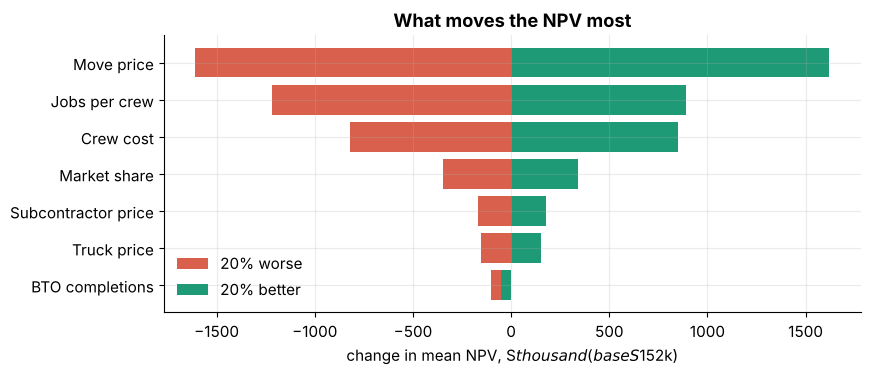

In [18]:
TOR = [('shareTarget', 'Market share', 1), ('priceHDB', 'Move price', 1), ('crewCost', 'Crew cost', -1), ('jobsPerCrew', 'Jobs per crew', 1),
       ('subFrac', 'Subcontractor price', -1), ('truckCapex', 'Truck price', -1), ('btoFuture', 'BTO completions', 1)]
base600 = run_strategy('phased', gen_scenarios(BASE, 600), BASE)['meanNPV']; tor = []
for k, nm, dr in TOR:
    w, bt_ = {**BASE, k: BASE[k] * (1 - 0.2 * dr)}, {**BASE, k: BASE[k] * (1 + 0.2 * dr)}
    tor.append((nm, run_strategy('phased', gen_scenarios(w, 600), w)['meanNPV'] - base600, run_strategy('phased', gen_scenarios(bt_, 600), bt_)['meanNPV'] - base600))
tor = pd.DataFrame(tor, columns=['assumption', '20% worse', '20% better']).set_index('assumption')
tor = tor.loc[(tor['20% better'] - tor['20% worse']).abs().sort_values().index]
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.barh(tor.index, tor['20% worse'] / 1e3, color=C2, label='20% worse'); ax.barh(tor.index, tor['20% better'] / 1e3, color=C1, label='20% better')
ax.set_xlabel(f'change in mean NPV, S$ thousand (base S${base600/1e3:,.0f}k)'); ax.set_title('What moves the NPV most'); ax.legend(frameon=False); plt.show()

**Stress test.** One fleet plan is made in advance from the "history repeats" forecast; each shock then arrives unannounced. Same 600 futures per row.

In [19]:
SCEN = [('Calm: no recession, rules frozen', dict(recMode='none', polMode='frozen')),
        ('History repeats (random shocks)', dict(recMode='random', polMode='random')),
        ('Recession in 2028', dict(recMode='stress', recYear=2028, polMode='frozen')),
        ('Rules tighten, July 2028', dict(recMode='none', polMode='tighten', polYear=2028)),
        ('Rules loosen, July 2028', dict(recMode='none', polMode='loosen', polYear=2028)),
        ('Recession 2028, then tightening 2029', dict(recMode='stress', recYear=2028, polMode='tighten', polYear=2029))]
aPlan = {**BASE, 'recMode': 'random', 'polMode': 'random'}; plan = run_strategy('phased', gen_scenarios(aPlan, 600), aPlan)['T']
st = []
for nm, kw in SCEN:
    a = {**BASE, 'recYear': 2028, 'polYear': 2028, **kw}; sc = gen_scenarios(a, 600); r = run_strategy('phased', sc, a, plan)
    st.append((nm, np.median(sc['res'][:, 48:60].sum(1) / 2), r['meanNPV'], r['pLoss'], r['cvar5']))
stress = pd.DataFrame(st, columns=['scenario', 'HDB resales 2031', 'mean NPV', 'chance of loss', 'worst 5% avg']).set_index('scenario')
display(stress.style.format({'HDB resales 2031': '{:,.0f}', 'mean NPV': sgd, 'chance of loss': '{:.0%}', 'worst 5% avg': sgd}))

,HDB resales 2031,mean NPV,chance of loss,worst 5% avg
scenario,,,,
"Calm: no recession, rules frozen","28,818","S$223,230",37%,"−S$2,307,763"
History repeats (random shocks),"29,157","S$151,733",38%,"−S$2,343,996"
Recession in 2028,"30,097","S$303,247",34%,"−S$2,170,149"
"Rules tighten, July 2028","28,178","S$83,776",41%,"−S$2,427,606"
"Rules loosen, July 2028","29,473","S$359,112",33%,"−S$2,183,164"
"Recession 2028, then tightening 2029","29,083","S$197,561",36%,"−S$2,275,239"


### 9b. Do the results depend on the random seed?
The simulation is seeded (seed 2027) so it reproduces exactly. To check that the conclusions are not an artefact of one seed, we re-run the four strategies with five different seeds (2,000 futures each).

In [20]:
seedrows = []
for seed in [2027, 1, 42, 777, 31337]:
    sc_ = gen_scenarios(BASE, 2000, seed)
    for s in STRATS:
        r = run_strategy(s, sc_, BASE); seedrows.append(dict(seed=seed, strategy=STRATS[s], meanNPV=r['meanNPV'], pLoss=r['pLoss']))
seedT = pd.DataFrame(seedrows).pivot_table(index='strategy', values=['meanNPV', 'pLoss'], aggfunc=['mean', 'min', 'max'])
display(seedT.style.format(lambda v: sgd(v) if abs(v) > 1 else f'{v:.1%}'))
best = pd.DataFrame(seedrows).loc[lambda x: x.groupby('seed').meanNPV.idxmax()].strategy.value_counts()
print('best strategy by seed:', best.to_dict())

best strategy by seed: {'Phased buying': 5}


**Reading it.** Phased buying has the best mean NPV under every seed. The exact figures move with the seed: phased buying's mean NPV ranges from about S$95k to S$208k and its chance of loss from about 37% to 40%. Seed 2027, used everywhere else, happens to sit at the favourable end, so the honest headline is "phased buying is best and roughly break-even to modestly profitable, with a 37–40% chance of loss". The ranking and the recommendation do not depend on the seed.

### Recommendation
* **Demand is predictable**: the MOP wave and the flat stock are already known; five years ahead the forecast errs by about 8% (vs 22% naive).
* **Size the fleet with the newsvendor rule** (own capacity for about the 58% quantile of monthly demand) and subcontract the peaks.
* **Buy trucks in phases**, never the whole fleet upfront: phased buying has the best mean NPV and the lowest chance of loss; buying upfront loses money in about 80% of futures.
* **Raise a cash buffer** of roughly the "cash needed" figure to survive the worst 5% of launches.
* **Shocks**: a surprise recession helps volume more than the price cut hurts; a rule tightening hurts more because it lasts. Watch market share and move price first (tornado).

## 10. Summary and app consistency check
### Key results

In [21]:
summary = pd.Series({
    'HDB resales analysed (1990 – Sep 2026)': f'{natL.sum():,.0f}',
    'Estimated household moves, 2025': f"{moves.loc[2025, 'total']:,.0f}",
    'Median forecast, estimated moves 2031 (10–90%)': f'{fan.loc[2031, 0.5]:,.0f} ({fan.loc[2031, 0.1]:,.0f}–{fan.loc[2031, 0.9]:,.0f})',
    'Forecast error 5 years ahead: model vs repeat-last-year': f"{rollT['our model'][5]:.1%} vs {rollT['repeat last year'][5]:.1%}",
    'Actual outcomes inside the 80% forecast band': f"{cov.in80.mean():.0%} of {len(cov)} tests",
    'Recession-year effect on HDB resales': f'{math.exp(bRec) - 1:+.1%}',
    'Effect of one major rule change': f'±{math.exp(bPol) - 1:.1%}',
    'Newsvendor critical ratio': f"{nv['CR']:.1%}",
    'Best strategy (all 5 seeds tested)': f"Phased buying: mean NPV {sgd(RES['phased']['meanNPV'])}, chance of loss {RES['phased']['pLoss']:.0%}",
    'Buying the whole fleet upfront': f"mean NPV {sgd(RES['buy']['meanNPV'])}, chance of loss {RES['buy']['pLoss']:.0%}",
    'Cash buffer to survive the worst 5% (phased)': sgd(RES['phased']['cashNeed'])}, name='result')
summary.to_frame()

,result
HDB resales analysed (1990 – Sep 2026),"987,903"
"Estimated household moves, 2025","118,622"
"Median forecast, estimated moves 2031 (10–90%)","125,253 (113,113–140,839)"
Forecast error 5 years ahead: model vs repeat-last-year,8.3% vs 22.1%
Actual outcomes inside the 80% forecast band,89% of 44 tests
Recession-year effect on HDB resales,+16.6%
Effect of one major rule change,±6.5%
Newsvendor critical ratio,58.3%
Best strategy (all 5 seeds tested),"Phased buying: mean NPV S$208,100, chance of l..."
Buying the whole fleet upfront,"mean NPV −S$1,097,588, chance of loss 81%"


### The interactive app reproduces these numbers
The app re-implements the models in JavaScript so its sliders can re-run them live. It uses the same random generator (mulberry32 + polar Box–Muller) and seed, so its numbers should match this notebook exactly. `APP` holds the values recorded from the built app (with base-case assumptions).

In [22]:
APP = {
 "E2026": 27201.567293202657,
 "E2031": 29749.63822156878,
 "hNow6": 0.04970286331712588,
 "phi": 0.4633005255785667,
 "mape": 0.11848520768798511,
 "roll5": 0.08260948490932257,
 "bRec": 0.15364016138711212,
 "bPol": 0.06303956773071685,
 "CR": 0.582584125353198,
 "inertia": 45.874231489986556,
 "moves2025": 118622.5,
 "npv": {
  "buy": -1097587.602904205,
  "lease": -246884.11663467967,
  "phased": 208100.41070034078,
  "broker": -338816.52248307737
 },
 "ploss": {
  "buy": 0.8085,
  "lease": 0.509,
  "phased": 0.373,
  "broker": 1
 },
 "stress": [
  223230.23848975272,
  151733.21657821632,
  303246.5923345521,
  83776.25499609062,
  359111.87931496673,
  197560.52031505885
 ]
}
chk = [('structural resales 2026', E(2026), APP['E2026']), ('structural resales 2031', E(2031), APP['E2031']),
       ('resale chance at age 6 (since 2011)', hNow(6), APP['hNow6']), ('market mood persistence', phi, APP['phi']),
       ('monthly test MAPE', metrics(pred)['MAPE'], APP['mape']), ('5-year backtest error', rollT['our model'][5], APP['roll5']),
       ('recession effect (log)', bRec, APP['bRec']), ('rule-change effect (log)', bPol, APP['bPol']),
       ('critical ratio', nv['CR'], APP['CR']), ('k = 4 cluster inertia', inertia, APP['inertia']),
       ('estimated moves 2025', moves.loc[2025, 'total'], APP['moves2025'])] \
    + [(f'{STRATS[s]}: mean NPV', RES[s]['meanNPV'], APP['npv'][s]) for s in STRATS] \
    + [(f'{STRATS[s]}: chance of loss', RES[s]['pLoss'], APP['ploss'][s]) for s in STRATS] \
    + [(f'stress: {n}', stress['mean NPV'][n], v) for n, v in zip(stress.index, APP['stress'])]
check = pd.DataFrame(chk, columns=['quantity', 'notebook', 'app']).set_index('quantity')
check['match'] = np.isclose(check.notebook, check.app, rtol=1e-6, atol=1e-6)
display(check.style.format({'notebook': '{:,.6g}', 'app': '{:,.6g}'}))
print('ALL MATCH' if check.match.all() else f'{(~check.match).sum()} mismatches (expected if USE_LIVE_DATA = True or assumptions were changed)')

,notebook,app,match
quantity,,,
structural resales 2026,"27,201.6","27,201.6",True
structural resales 2031,"29,749.6","29,749.6",True
resale chance at age 6 (since 2011),0.0497029,0.0497029,True
market mood persistence,0.463301,0.463301,True
monthly test MAPE,0.118485,0.118485,True
5-year backtest error,0.0826095,0.0826095,True
recession effect (log),0.15364,0.15364,True
rule-change effect (log),0.0630396,0.0630396,True
critical ratio,0.582584,0.582584,True


ALL MATCH
